# **Dynamic Complex Networks Project**

In [1]:
!pip install yfinance networkx python-louvain matplotlib pandas

In [2]:
import yfinance as yf
import pandas as pd

tickers = [
    'AAPL', 'MSFT', 'GOOGL', 'AMZN', 'META', 'TSLA', 'NVDA', 'NFLX',
    'JPM', 'BAC', 'WFC', 'GS', 'MS', 'V', 'MA',
    'JNJ', 'PFE', 'MRK', 'UNH', 'ABBV',
    'XOM', 'CVX', 'COP', 'SLB',
    'WMT', 'PG', 'KO', 'PEP', 'HD', 'MCD',
    'BA', 'CAT', 'GE']

data = yf.download(tickers, start="2019-01-01", end="2024-01-01")

prices = data['Close']


print(prices.head())

[*********************100%***********************]  33 of 33 completed

Ticker           AAPL       ABBV       AMZN          BA        BAC  \
Date                                                                 
2019-01-02  37.436920  63.938931  76.956497  314.645172  20.731050   
2019-01-03  33.707932  61.832233  75.014000  302.100555  20.398819   
2019-01-04  35.146893  63.824272  78.769501  317.822601  21.246004   
2019-01-07  35.068665  64.755791  81.475502  318.823425  21.229389   
2019-01-08  35.737186  65.056770  82.829002  330.891907  21.187860   

Ticker             CAT        COP        CVX         GE      GOOGL  ...  \
Date                                                                ...   
2019-01-02  107.567764  48.707333  79.181641  37.214649  52.236927  ...   
2019-01-03  103.422676  47.785133  77.665108  37.260872  50.790192  ...   
2019-01-04  109.074265  48.991676  79.274643  38.046783  53.395401  ...   
2019-01-07  109.142365  48.776501  80.304733  40.404465  53.288921  ...   
2019-01-08  110.453125  49.429726  79.954201  39.572338  53

In [3]:
returns = prices.pct_change().dropna()


corr_matrix = returns.corr()

print(corr_matrix.iloc[:4, :4])

Ticker      AAPL      ABBV      AMZN        BA
Ticker                                        
AAPL    1.000000  0.337084  0.619210  0.416347
ABBV    0.337084  1.000000  0.196016  0.267619
AMZN    0.619210  0.196016  1.000000  0.280402
BA      0.416347  0.267619  0.280402  1.000000


In [4]:
import networkx as nx
threshold = 0.7

G = nx.Graph()


G.add_nodes_from(corr_matrix.columns)


for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        if abs(corr_matrix.iloc[i, j]) > threshold:
            stock1 = corr_matrix.columns[i]
            stock2 = corr_matrix.columns[j]
            G.add_edge(stock1, stock2, weight=corr_matrix.iloc[i, j])

print(f"number of nodes: {G.number_of_nodes()}")
print(f"number of edges: {G.number_of_edges()}")

number of nodes: 33
number of edges: 22


In [5]:
import community as community_louvain


partition = community_louvain.best_partition(G)


modularity_score = community_louvain.modularity(partition, G)
print(f"score of  Modularity: {modularity_score:.4f}")



print("\n communities :")
communities = {}
for node, com_id in partition.items():
    if com_id not in communities:
        communities[com_id] = []
    communities[com_id].append(node)

for com_id, members in communities.items():
    print(f"community {com_id}: {members}")

score of  Modularity: 0.6824

 communities :
community 9: ['AAPL', 'GOOGL', 'MSFT', 'NVDA']
community 1: ['ABBV']
community 2: ['AMZN']
community 3: ['BA']
community 10: ['BAC', 'GS', 'JPM', 'MS', 'WFC']
community 5: ['CAT']
community 0: ['COP', 'CVX', 'SLB', 'XOM']
community 8: ['GE']
community 11: ['HD']
community 12: ['JNJ']
community 7: ['KO', 'PEP', 'PG']
community 15: ['MA', 'V']
community 16: ['MCD']
community 17: ['META']
community 18: ['MRK']
community 4: ['NFLX']
community 6: ['PFE']
community 13: ['TSLA']
community 14: ['UNH']
community 19: ['WMT']


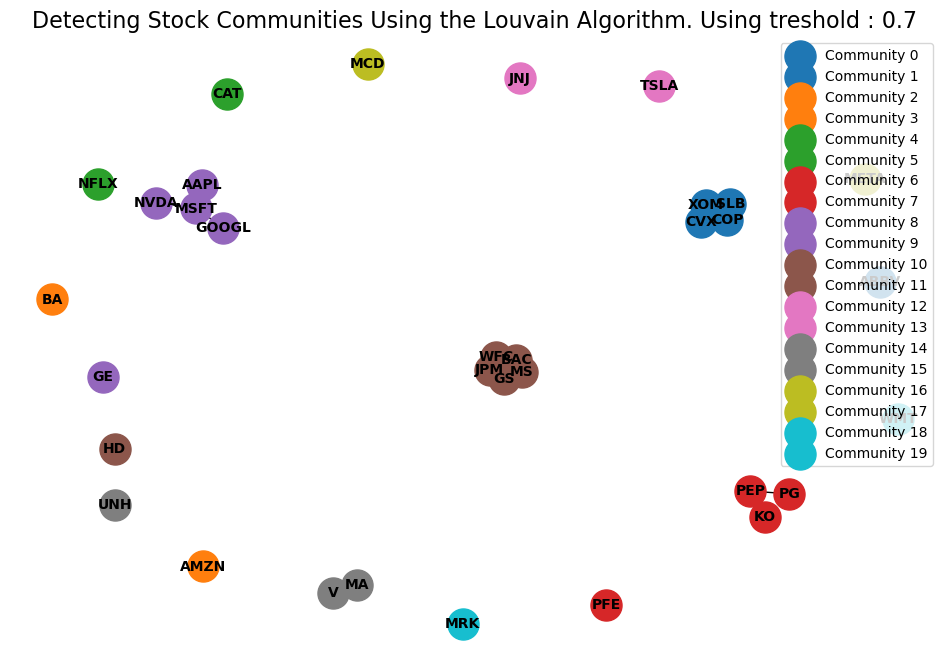

In [6]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm

pos = nx.spring_layout(G, seed=42)


num_communities = len(set(partition.values()))
colors = [cm.tab10(i / num_communities) for i in range(num_communities)]

plt.figure(figsize=(12, 8))

nx.draw_networkx_edges(G, pos, alpha=1)


for com_id in set(partition.values()):
    list_nodes = [nodes for nodes in partition.keys() if partition[nodes] == com_id]
    nx.draw_networkx_nodes(G, pos, list_nodes, node_size=500,
                           node_color=[colors[com_id]], label=f"Community {com_id}")


nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')

plt.title(f"Detecting Stock Communities Using the Louvain Algorithm. Using treshold : {threshold}", fontsize=16)
plt.legend()
plt.axis('off')
plt.show()

## Configuration Lab: how robust are the discovered communities?

The original analysis uses one correlation threshold and one Louvain configuration. In this section, we test whether the observed structure is robust to reasonable choices. We compare network sparsity, modularity, community size, centrality, correlation methods, and rolling time windows.

In [7]:
import numpy as np

def build_correlation_graph(correlation, threshold):
    """Build an undirected graph while keeping correlation sign and magnitude."""
    graph = nx.Graph()
    graph.add_nodes_from(correlation.columns)
    for i, first in enumerate(correlation.columns):
        for second in correlation.columns[i + 1:]:
            value = float(correlation.loc[first, second])
            if abs(value) >= threshold:
                graph.add_edge(first, second, weight=abs(value), correlation=value)
    return graph

def analyze_configuration(correlation, threshold, resolution=1.0, seed=42):
    graph = build_correlation_graph(correlation, threshold)
    if graph.number_of_edges() == 0:
        partition = {node: index for index, node in enumerate(graph.nodes)}
        modularity = 0.0
    else:
        partition = community_louvain.best_partition(
            graph, weight="weight", resolution=resolution, random_state=seed
        )
        modularity = community_louvain.modularity(partition, graph, weight="weight")
    community_sizes = pd.Series(partition).value_counts()
    return {
        "threshold": threshold,
        "resolution": resolution,
        "nodes": graph.number_of_nodes(),
        "edges": graph.number_of_edges(),
        "density": nx.density(graph),
        "communities": community_sizes.size,
        "largest_community": int(community_sizes.max()),
        "modularity": modularity,
        "graph": graph,
        "partition": partition,
    }

thresholds = [0.50, 0.60, 0.70, 0.80, 0.90]
resolutions = [0.70, 1.00, 1.30]
experiments = [
    analyze_configuration(corr_matrix, threshold, resolution)
    for threshold in thresholds
    for resolution in resolutions
]
experiment_table = pd.DataFrame(experiments).drop(columns=["graph", "partition"])
experiment_table.sort_values("modularity", ascending=False).head(10)

,threshold,resolution,nodes,edges,density,communities,largest_community,modularity
6,0.7,0.7,33,22,0.041667,20,5,0.682394
8,0.7,1.3,33,22,0.041667,20,5,0.682394
7,0.7,1.0,33,22,0.041667,20,5,0.682394
10,0.8,1.0,33,13,0.024621,25,5,0.524063
9,0.8,0.7,33,13,0.024621,25,5,0.524063
11,0.8,1.3,33,13,0.024621,25,5,0.524063
12,0.9,0.7,33,2,0.003788,31,2,0.499991
13,0.9,1.0,33,2,0.003788,31,2,0.499991
14,0.9,1.3,33,2,0.003788,31,2,0.499991
4,0.6,1.0,33,62,0.117424,12,10,0.483252


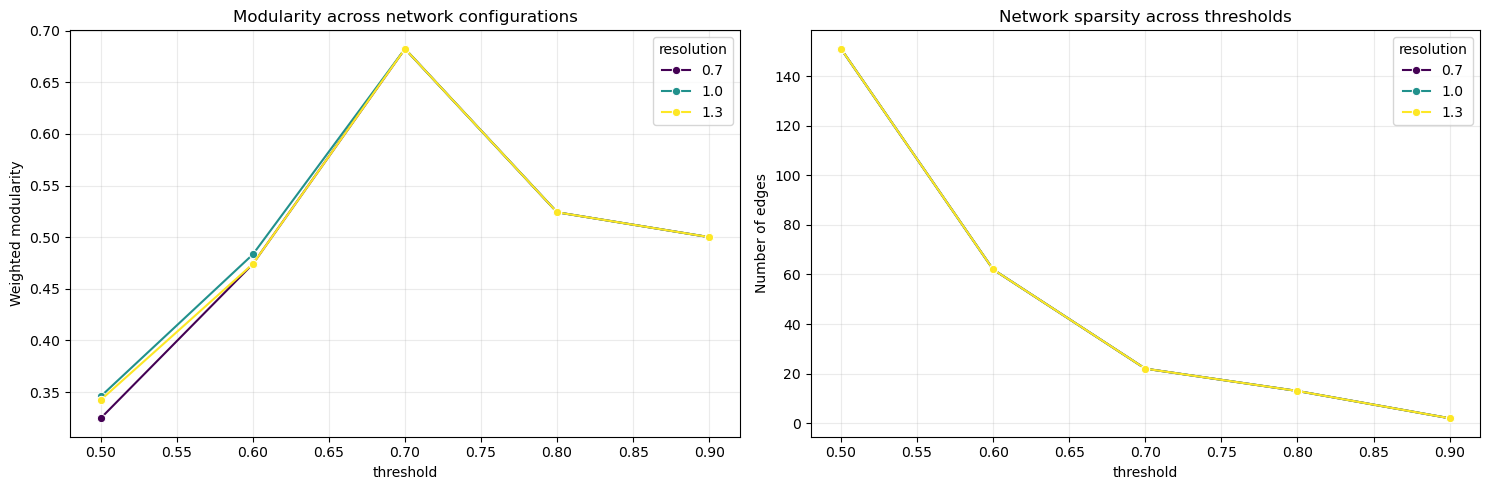

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for resolution, group in experiment_table.groupby("resolution"):
    axes[0].plot(group["threshold"], group["modularity"], marker="o", label=f"resolution={resolution}")
axes[0].legend(title="Louvain")
axes[0].set_title("Modularity across network configurations")
axes[0].set_ylabel("Weighted modularity")
axes[0].grid(alpha=0.25)

for resolution, group in experiment_table.groupby("resolution"):
    axes[1].plot(group["threshold"], group["edges"], marker="o", label=f"resolution={resolution}")
axes[1].legend(title="Louvain")
axes[1].set_title("Network sparsity across thresholds")
axes[1].set_ylabel("Number of edges")
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()

### A second view of dependence: Pearson versus Spearman

Pearson captures linear co-movement, while Spearman captures monotonic dependence and is less sensitive to extreme daily returns. Comparing both helps distinguish a stable relationship from one driven by a few outliers.

,threshold,resolution,nodes,edges,density,communities,largest_community,modularity,method
0,0.5,1.0,33,151,0.285985,4,12,0.345736,Pearson
1,0.6,1.0,33,62,0.117424,12,10,0.483252,Pearson
2,0.7,1.0,33,22,0.041667,20,5,0.682394,Pearson
3,0.8,1.0,33,13,0.024621,25,5,0.524063,Pearson
4,0.9,1.0,33,2,0.003788,31,2,0.499991,Pearson
5,0.5,1.0,33,88,0.166667,8,12,0.528289,Spearman
6,0.6,1.0,33,42,0.079545,16,8,0.622664,Spearman
7,0.7,1.0,33,20,0.037879,22,5,0.640496,Spearman
8,0.8,1.0,33,10,0.018939,26,5,0.545770,Spearman
9,0.9,1.0,33,0,0.000000,33,1,0.000000,Spearman


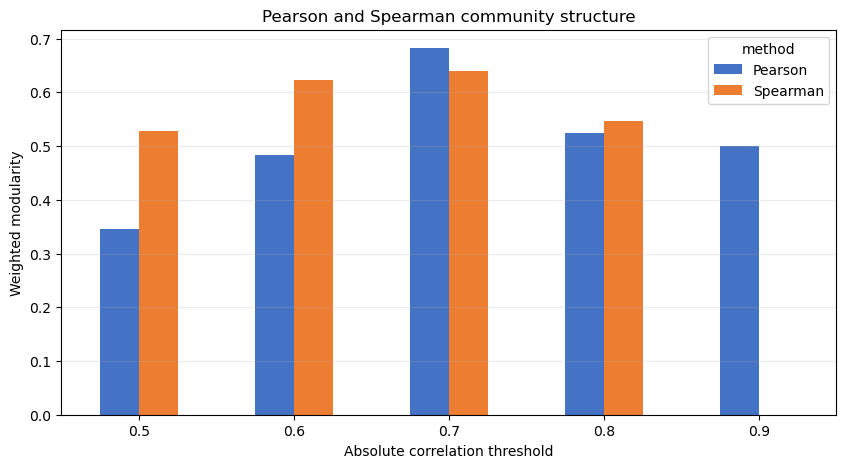

In [9]:
correlation_methods = {
    "Pearson": returns.corr(method="pearson"),
    "Spearman": returns.corr(method="spearman"),
}
method_results = []
for method_name, correlation in correlation_methods.items():
    for threshold in thresholds:
        result = analyze_configuration(correlation, threshold, resolution=1.0)
        result["method"] = method_name
        method_results.append(result)

method_table = pd.DataFrame(method_results).drop(columns=["graph", "partition"])
display(method_table)

comparison = method_table.pivot(index="threshold", columns="method", values="modularity")
comparison.plot(kind="bar", figsize=(10, 5), color=["#4472C4", "#ED7D31"])
plt.title("Pearson and Spearman community structure")
plt.ylabel("Weighted modularity")
plt.xlabel("Absolute correlation threshold")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.25)
plt.show()

In [ ]:
selected = analyze_configuration(corr_matrix, threshold=0.70, resolution=1.0)
selected_graph = selected["graph"]

eigenvector = {}
for component in nx.connected_components(selected_graph):
    component_graph = selected_graph.subgraph(component)
    eigenvector.update(
        nx.eigenvector_centrality(component_graph, max_iter=1000, weight="weight")
    )

centrality = pd.DataFrame({
    "degree": nx.degree_centrality(selected_graph),
    "weighted_degree": dict(selected_graph.degree(weight="weight")),
    "betweenness": nx.betweenness_centrality(selected_graph, weight="weight"),
    "eigenvector": eigenvector,
}).sort_values("weighted_degree", ascending=False)

print("Most central assets in the threshold=0.70 network:")
display(centrality.head(10).round(3))

top_assets = centrality.head(10).sort_values("weighted_degree")
top_assets["weighted_degree"].plot(kind="barh", figsize=(8, 5), color="#5B9BD5")
plt.title("Top assets by weighted network degree")
plt.xlabel("Sum of absolute correlations")
plt.tight_layout()
plt.show()

### Rolling-window stability

A single full-period correlation matrix can hide regime changes. We therefore repeat the same experiment in overlapping 252-trading-day windows and track the number of edges and modularity over time.

,threshold,resolution,nodes,edges,density,communities,largest_community,modularity,window_start,window_end
0,0.7,1.0,33,12,0.022727,25,5,0.529957,2019-01-03,2020-01-02
1,0.7,1.0,33,140,0.265152,7,11,0.248261,2019-07-05,2020-07-02
2,0.7,1.0,33,110,0.208333,6,12,0.348791,2020-01-03,2020-12-31
3,0.7,1.0,33,18,0.034091,23,5,0.624254,2020-07-06,2021-07-02
4,0.7,1.0,33,18,0.034091,23,5,0.627936,2021-01-04,2021-12-31
5,0.7,1.0,33,24,0.045455,20,5,0.735620,2021-07-06,2022-07-05
6,0.7,1.0,33,31,0.058712,18,7,0.700328,2022-01-03,2023-01-03
7,0.7,1.0,33,22,0.041667,20,6,0.691950,2022-07-06,2023-07-06


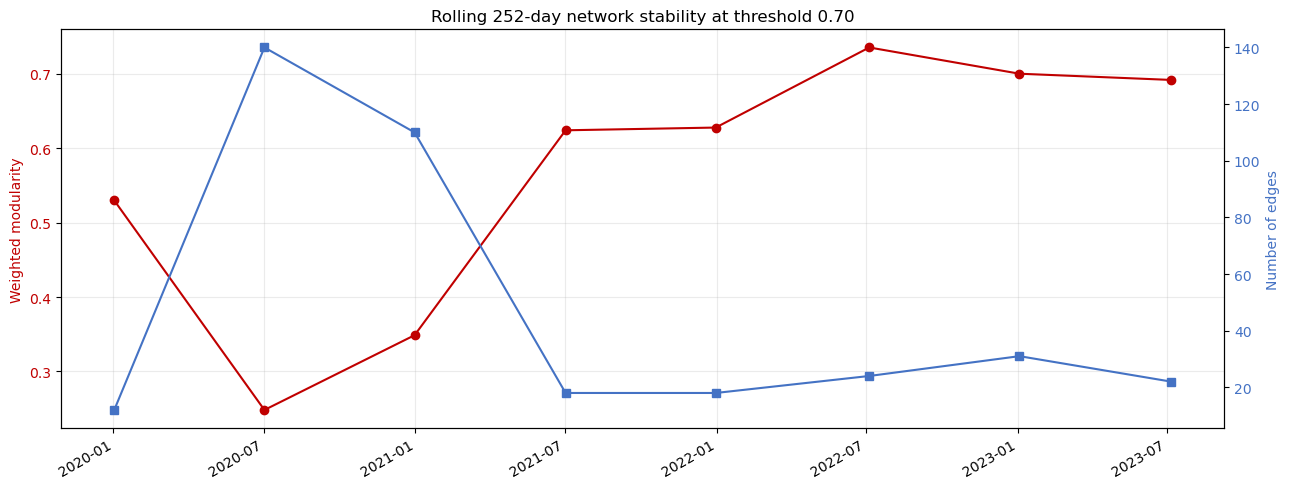

In [ ]:
window_size = 252
step = 126
rolling_records = []
for start in range(0, len(returns) - window_size + 1, step):
    window = returns.iloc[start:start + window_size]
    window_correlation = window.corr()
    result = analyze_configuration(window_correlation, threshold=0.70, resolution=1.0)
    result["window_start"] = window.index[0]
    result["window_end"] = window.index[-1]
    rolling_records.append(result)

rolling_table = pd.DataFrame(rolling_records).drop(columns=["graph", "partition"])
display(rolling_table)

fig, ax1 = plt.subplots(figsize=(13, 5))
ax1.plot(rolling_table["window_end"], rolling_table["modularity"], marker="o", color="#C00000")
ax1.set_ylabel("Weighted modularity", color="#C00000")
ax1.tick_params(axis="y", labelcolor="#C00000")
ax1.grid(alpha=0.25)
ax2 = ax1.twinx()
ax2.plot(rolling_table["window_end"], rolling_table["edges"], marker="s", color="#4472C4")
ax2.set_ylabel("Number of edges", color="#4472C4")
ax2.tick_params(axis="y", labelcolor="#4472C4")
plt.title("Rolling 252-day network stability at threshold 0.70")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()